In [3]:
import glob
import kagglehub
import pandas as pd

# Download the full dataset directory
path = kagglehub.dataset_download("bwandowando/clash-royale-season-18-dec-0320-dataset")

# Match all battle CSVs across all staging subdirectories
battle_csv_files = glob.glob(f"{path}/*_WL_tagged/*.csv")

# Load all datasets
df_list = [pd.read_csv(f) for f in battle_csv_files]
df = pd.concat(df_list, ignore_index=True)

/Users/u71072/Desktop/ISYE6416-Final-Project/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


 22%|██▏       | 1.12G/5.03G [00:32<01:51, 37.5MB/s]


KeyboardInterrupt: 

In [ ]:
# For each row, print if there are "NotANumber" values
for col, is_na in df.isna().any().items():
    print(f'{col}: {is_na}')


Unnamed: 0: False
battleTime: False
arena.id: False
gameMode.id: False
average.startingTrophies: False
winner.tag: False
winner.startingTrophies: False
winner.trophyChange: False
winner.crowns: False
winner.kingTowerHitPoints: False
winner.princessTowersHitPoints: True
winner.clan.tag: True
winner.clan.badgeId: True
loser.tag: False
loser.startingTrophies: False
loser.trophyChange: False
loser.crowns: False
loser.kingTowerHitPoints: True
loser.clan.tag: True
loser.clan.badgeId: True
loser.princessTowersHitPoints: True
tournamentTag: True
winner.card1.id: False
winner.card1.level: False
winner.card2.id: False
winner.card2.level: False
winner.card3.id: False
winner.card3.level: False
winner.card4.id: False
winner.card4.level: False
winner.card5.id: False
winner.card5.level: False
winner.card6.id: False
winner.card6.level: False
winner.card7.id: False
winner.card7.level: False
winner.card8.id: False
winner.card8.level: False
winner.cards.list: False
winner.totalcard.level: False
winner.tr

# NaN Values:

Only ones that have missing numbers are categorical and not really important relevant to our research:

```
winner.princessTowersHitPoints: True
winner.clan.tag: True
winner.clan.badgeId: True
loser.kingTowerHitPoints: True
loser.clan.tag: True
loser.clan.badgeId: True
loser.princessTowersHitPoints: True
tournamentTag: True
```

# Loser vs. Winner data:

The dataset contains both loser and winner data (cards, deck, levels, trophies, etc...). I think, specifically because we want to see competitive meta-play, we would rather focus on the winner's deck and trophy count.

# Useful for Tauhid:

Note that the `winner.cards.list` contains the exact deck the winner used in the format:

```
[card_id_1, card_id_2, card_id_3, card_id_4, card_id_5, card_id_6, card_id_7, card_id_8]
```

In [ ]:
# Sort best players by STARTING TROPHIES
df_first_sorted = df.sort_values(by="winner.startingTrophies", ascending=False)
# Get first 1000 players
df_best_players_sorted = df_first_sorted[:1000]

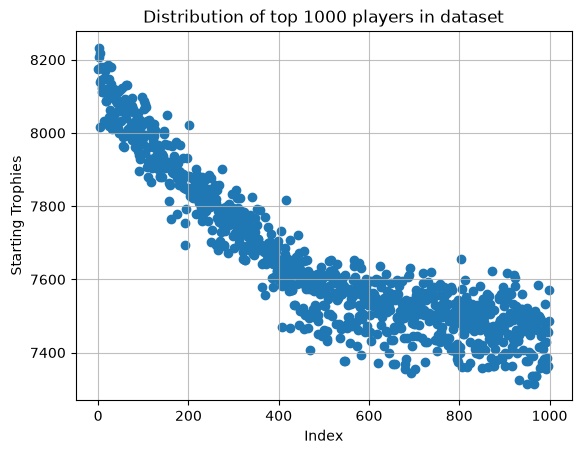

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Show scatter plot
plt.scatter(x=np.arange(len(df_best_players_sorted)), y=df_best_players_sorted["loser.startingTrophies"])
plt.title('Distribution of top 1000 players in dataset')
plt.xlabel('Index')
plt.ylabel('Starting Trophies')
plt.grid(True,alpha=0.8);

In [ ]:
# Save to CSV:
df_best_players_sorted.to_csv("1000_best_players.csv",index=False)

# Sparse Matrix Creation (Start from here, Vikranth)

In [ ]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix

#Load the card master list (M = 102 cards) and match sample (N = 1000 matches)
cards_df = pd.read_csv('CardMasterListSeason18.csv')
players_df = pd.read_csv('1000_best_players.csv')

print(f"Card catalog shape: {cards_df.shape}")
print(f"Match dataset shape: {players_df.shape}")
print(f"Unique winner tags across 1,000 matches: {players_df['winner.tag'].nunique()}")

Card catalog shape: (102, 2)
Match dataset shape: (1000, 74)
Unique winner tags across 1,000 matches: 222


In [9]:
# Define the 8 winning card ID columns
card_id_cols = [f'winner.card{i}.id' for i in range(1, 9)]

# Create an index mapper from the master card ID list and extract card names
card_id_index = pd.Index(cards_df['team.card1.id'])
card_names = cards_df['team.card1.name'].tolist()

# Verify that every card ID in the match dataset exists in the master list
used_card_ids = np.unique(players_df[card_id_cols].values)
missing_ids = np.setdiff1d(used_card_ids, card_id_index.values)
assert len(missing_ids) == 0, f"Unmapped card IDs found: {missing_ids}"

In [10]:
n_rows = len(players_df)
n_cols = len(cards_df)

# Each match row contributes exactly 8 non-zero entries
row_indices = np.repeat(np.arange(n_rows), 8)

# Map the flattened (1000 x 8) card IDs to their corresponding (0 to 101) column indices
col_indices = card_id_index.get_indexer(players_df[card_id_cols].values.flatten())

# Populate non-zero values with 1s
data = np.ones(len(row_indices), dtype=np.int8)

# Build the N x M Compressed Sparse Row (CSR) matrix
X_sparse = csr_matrix((data, (row_indices, col_indices)), shape=(n_rows, n_cols))

# Sanity check: verify dimensions, total non-zero elements, and row-sum constraint (= 8)
print(f"Sparse Matrix Shape: {X_sparse.shape}")
print(f"Total Non-Zero Entries (nnz): {X_sparse.nnz}")
assert np.all(X_sparse.sum(axis=1) == 8), "Row sum constraint violated!"

Sparse Matrix Shape: (1000, 102)
Total Non-Zero Entries (nnz): 8000


In [11]:
# Wrap the SciPy CSR matrix in a labeled Pandas Sparse DataFrame
deck_sparse_df = pd.DataFrame.sparse.from_spmatrix(
    X_sparse,
    index=players_df['winner.tag'],
    columns=card_names
)

# Display the first 5 rows and first 10 card columns
display(deck_sparse_df.iloc[:5, :10])

,Knight,Archers,Goblins,Giant,P.E.K.K.A,Minions,Balloon,Witch,Barbarians,Golem
winner.tag,,,,,,,,,,
#290QP2C,1,0,0,0,0,0,0,0,0,0
#YP9VPGUUG,0,0,0,0,0,0,1,0,0,0
#9RGQ8YC,0,0,0,0,0,0,0,0,0,0
#20QLJ2CLP,0,0,0,0,0,0,0,0,0,0
#GYUQQCLV,0,0,0,0,1,0,1,0,0,0
